# Experimental results

Figures and tables produced by `experiments/run_experiments.py` and `algorithms/quantum_algorithms.py`. Re-run those scripts to regenerate the data (`results/*.csv`). This notebook only loads and displays them.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display
R = ROOT / 'results'

## E1 - QBER and detection vs. Eve's intercept fraction

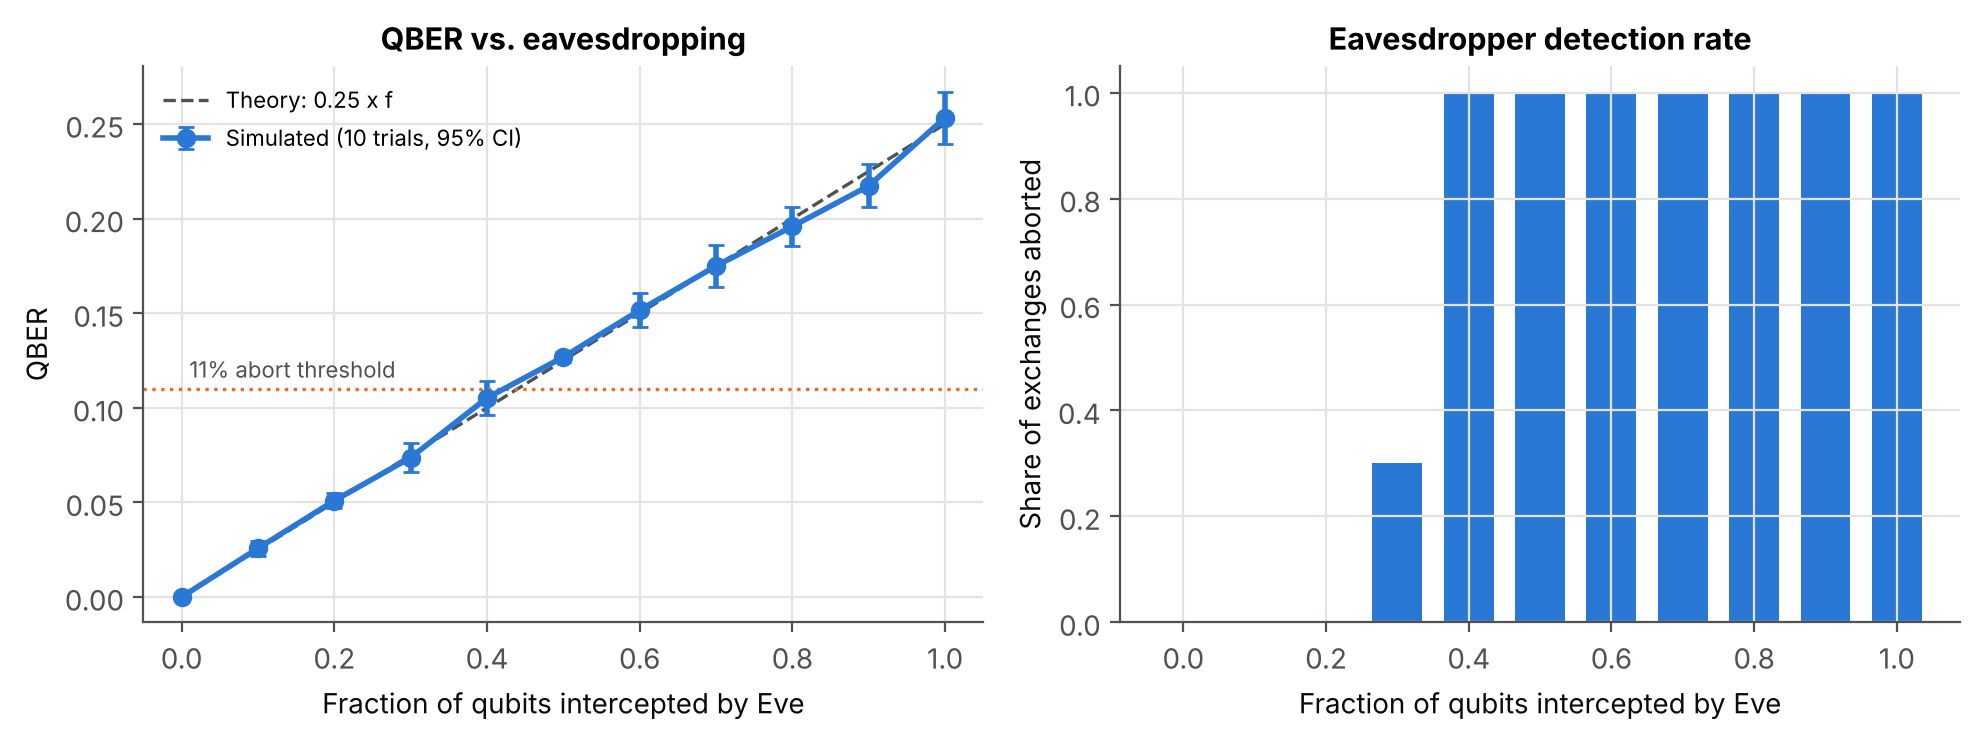

,qber_true,aborted,final_length
intercept_fraction,,,
0.0,0.0000,0.0,672.2
0.1,0.0257,0.0,382.8
0.2,0.0509,0.0,185.1
0.3,0.0737,0.3,49.5
0.4,0.1052,1.0,0.0
0.5,0.1268,1.0,0.0
0.6,0.1516,1.0,0.0
0.7,0.1750,1.0,0.0
0.8,0.1959,1.0,0.0


In [2]:
display(Image(R / 'e1_qber_vs_eve.png'))
pd.read_csv(R / 'e1_qber_vs_eve.csv').groupby('intercept_fraction')[['qber_true', 'aborted', 'final_length']].mean().round(4)

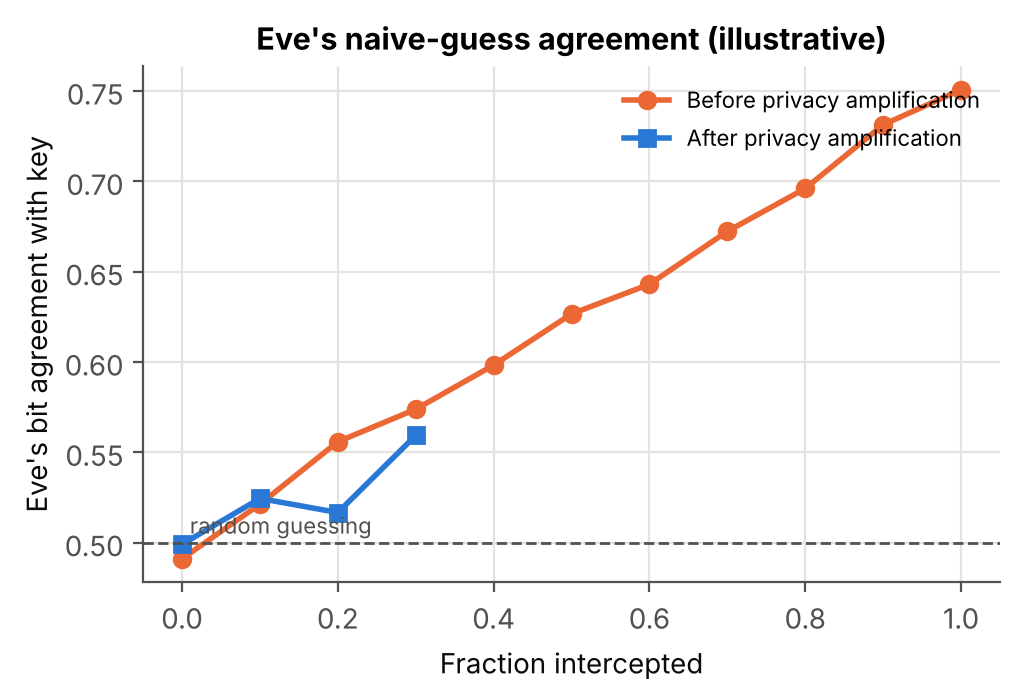

In [3]:
display(Image(R / 'e1b_eve_knowledge.png', width=520))

## E2 - Channel noise and secret-key rate

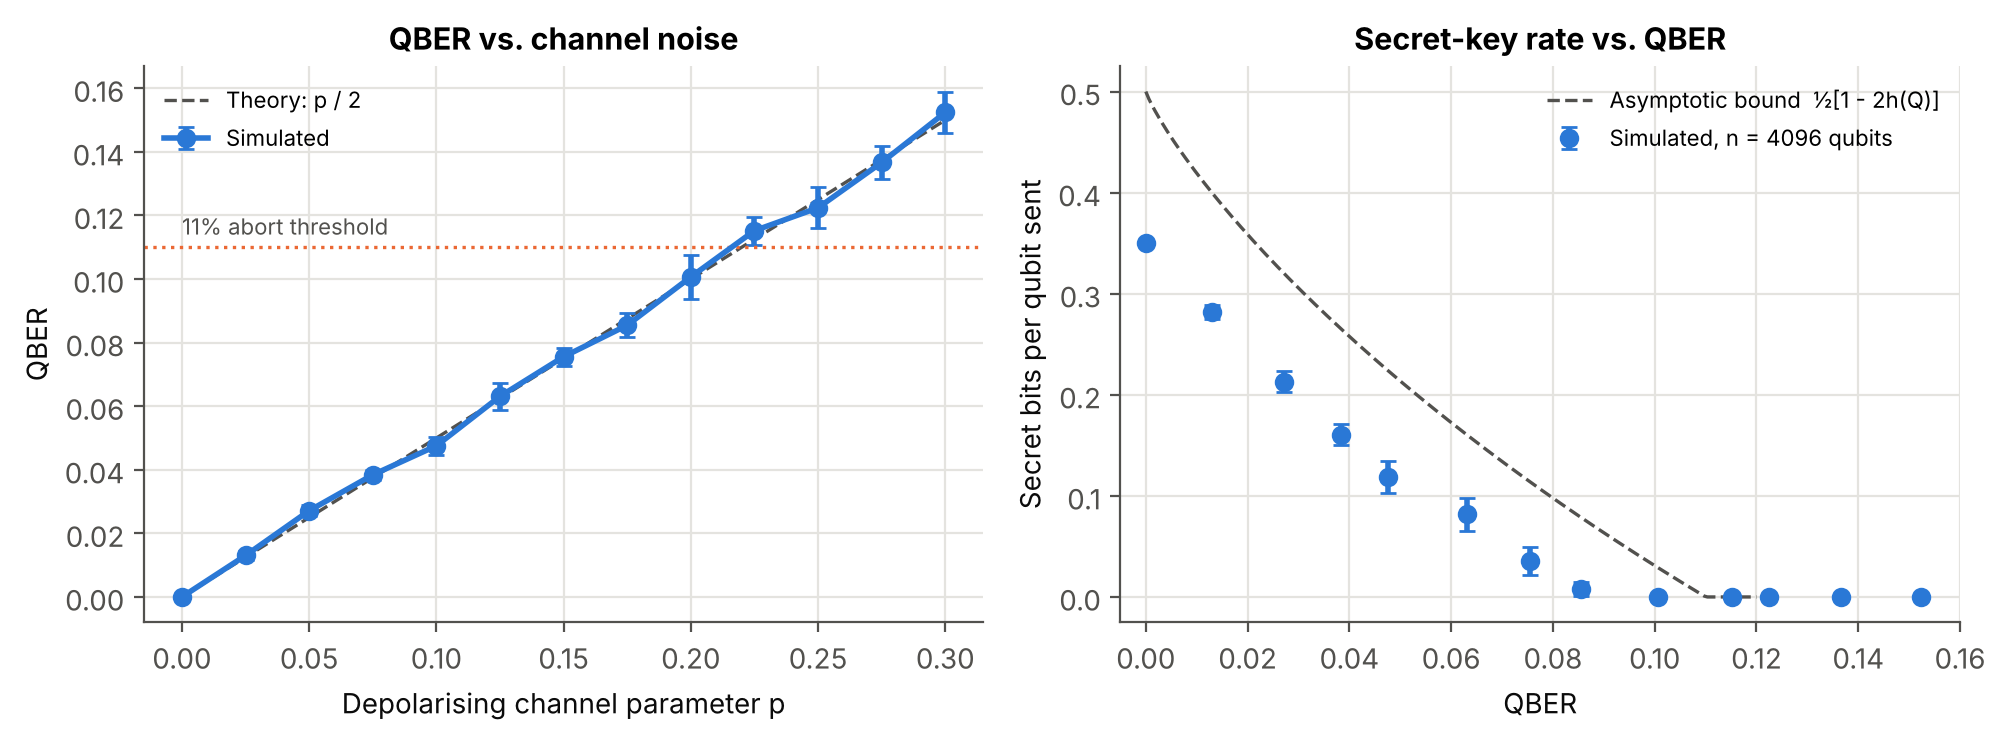

,expected_qber,qber_true,key_rate,aborted
channel_p,,,,
0.000,0.0000,0.0000,0.3498,0.0
0.025,0.0125,0.0130,0.2816,0.0
0.050,0.0250,0.0271,0.2129,0.0
0.075,0.0375,0.0384,0.1606,0.0
0.100,0.0500,0.0475,0.1188,0.0
0.125,0.0625,0.0631,0.0817,0.0
0.150,0.0750,0.0756,0.0357,0.1
0.175,0.0875,0.0855,0.0079,0.5
0.200,0.1000,0.1007,0.0000,1.0


In [4]:
display(Image(R / 'e2_noise.png'))
pd.read_csv(R / 'e2_noise.csv').groupby('channel_p')[['expected_qber', 'qber_true', 'key_rate', 'aborted']].mean().round(4)

## E3 - How many sampled bits are needed to catch Eve?

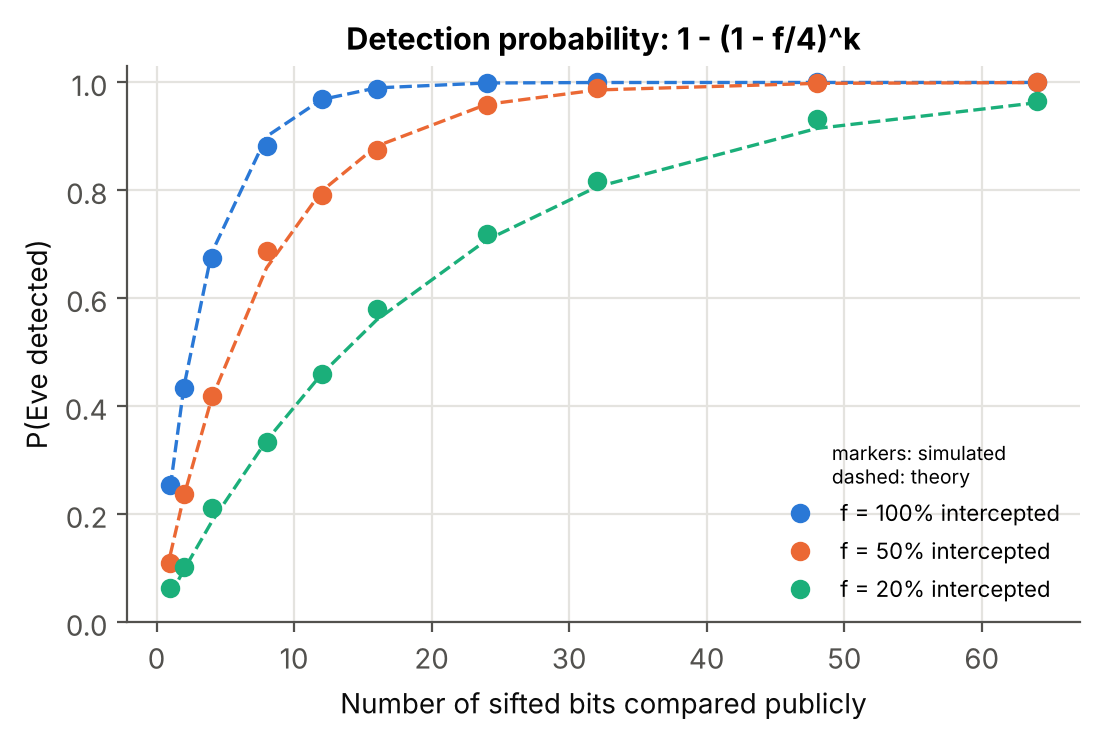

intercept_fraction,0.2,0.5,1.0
sample_bits,,,
1,0.0640,0.1100,0.2550
2,0.1020,0.2380,0.4335
4,0.2125,0.4185,0.6755
8,0.3345,0.6880,0.8820
12,0.4590,0.7920,0.9700
16,0.5800,0.8745,0.9870
24,0.7185,0.9575,0.9990
32,0.8180,0.9895,1.0000
48,0.9330,0.9995,1.0000


In [5]:
display(Image(R / 'e3_detection.png', width=560))
pd.read_csv(R / 'e3_detection.csv').pivot(index='sample_bits', columns='intercept_fraction', values='empirical')

## E4 - Run time and simulator methods

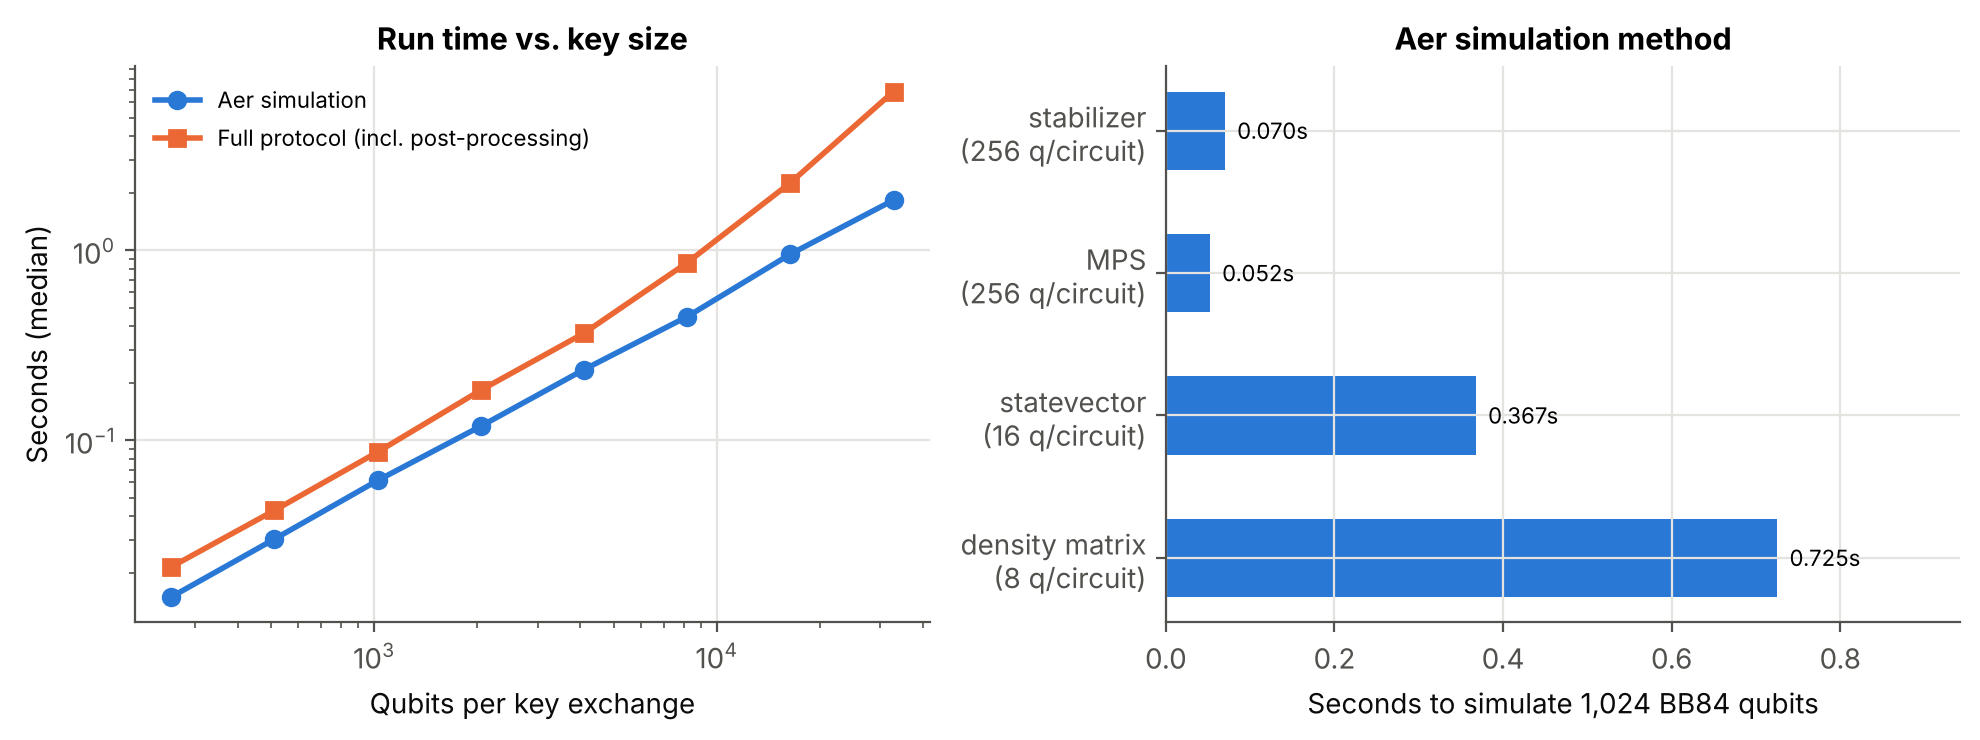

,n_qubits,simulate_s,total_s,final_length
0,256,0.014990,0.021579,0
1,512,0.030230,0.042788,95
2,1024,0.061492,0.086819,289
3,2048,0.118706,0.183680,647
4,4096,0.235737,0.366317,1433
5,8192,0.447624,0.860827,2969
6,16384,0.954648,2.266107,6074
7,32768,1.837354,6.848710,12224


,method,qubits_per_circuit,circuits,seconds_per_1024_qubits
0,stabilizer,256,4,0.069698
1,matrix_product_state,256,4,0.051895
2,statevector,16,64,0.367376
3,density_matrix,8,128,0.724918


In [6]:
display(Image(R / 'e4_scaling.png'))
display(pd.read_csv(R / 'e4_scaling.csv'))
pd.read_csv(R / 'e4_methods.csv')

## E5 - IBM device noise snapshots

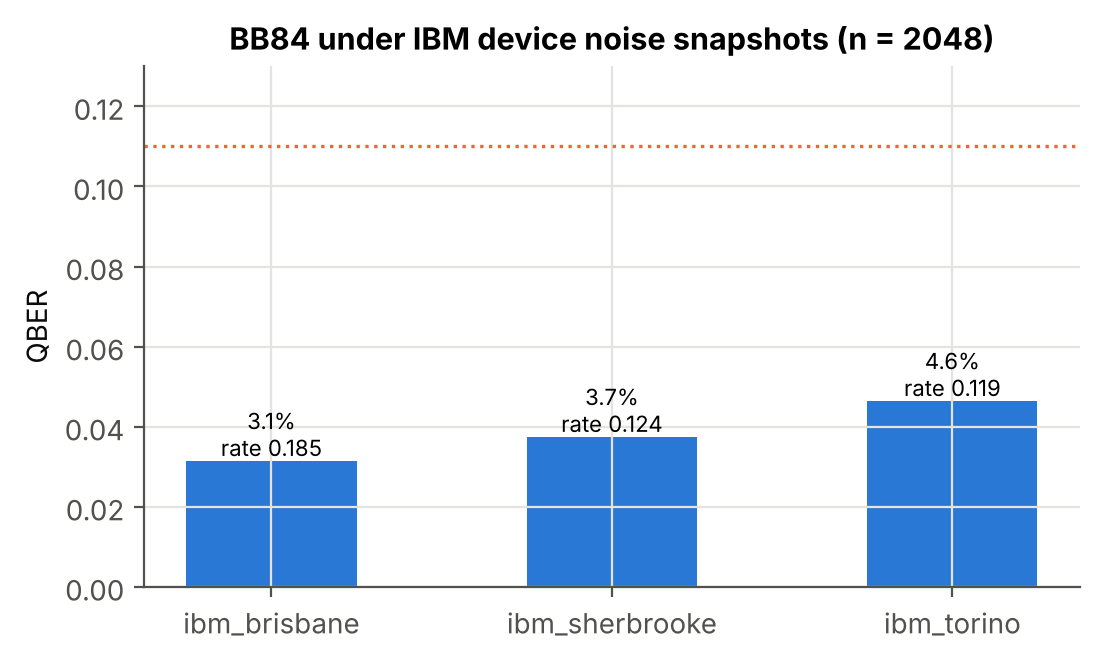

,qber_true,key_rate,final_length,simulate_s
backend,,,,
fake_brisbane,0.0314,0.1852,379.3333,2.5221
fake_sherbrooke,0.0374,0.1239,253.6667,2.4940
fake_torino,0.0463,0.1187,243.0000,3.7967


In [7]:
display(Image(R / 'e5_hardware.png', width=560))
pd.read_csv(R / 'e5_hardware.csv').groupby('backend')[['qber_true', 'key_rate', 'final_length', 'simulate_s']].mean().round(4)

## E6 - Cascade reconciliation efficiency

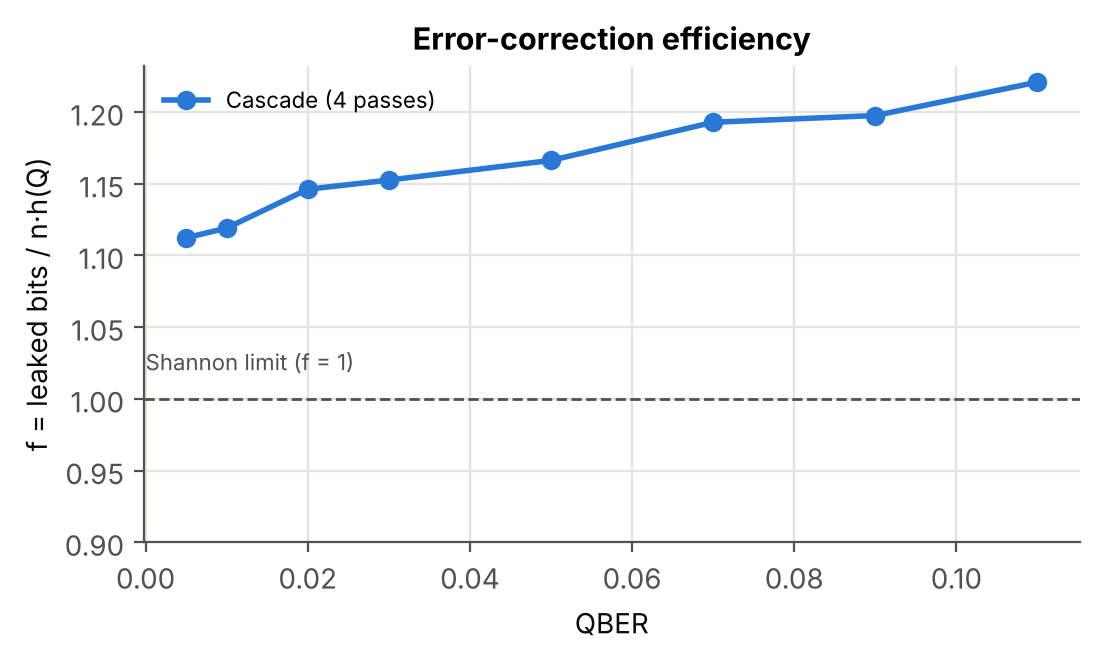

,efficiency_f,success
qber,,
0.005,1.112,1.0
0.010,1.119,1.0
0.020,1.146,1.0
0.030,1.153,1.0
0.050,1.166,1.0
0.070,1.193,1.0
0.090,1.198,1.0
0.110,1.221,1.0


In [8]:
display(Image(R / 'e6_cascade.png', width=560))
pd.read_csv(R / 'e6_cascade.csv').groupby('qber')[['efficiency_f', 'success']].mean().round(3)

## E7 - Classical baseline (X25519) vs. simulated BB84

In [9]:
pd.read_csv(R / 'e7_classical_vs_quantum.csv').T

,0
x25519_ms_per_key,0.198729
bb84_sim_ms_per_exchange_1024q,86.709713
bb84_qubits_per_256bit_key,914.990570
x25519_public_bytes,64.000000


## Selected quantum algorithms (objective 3)

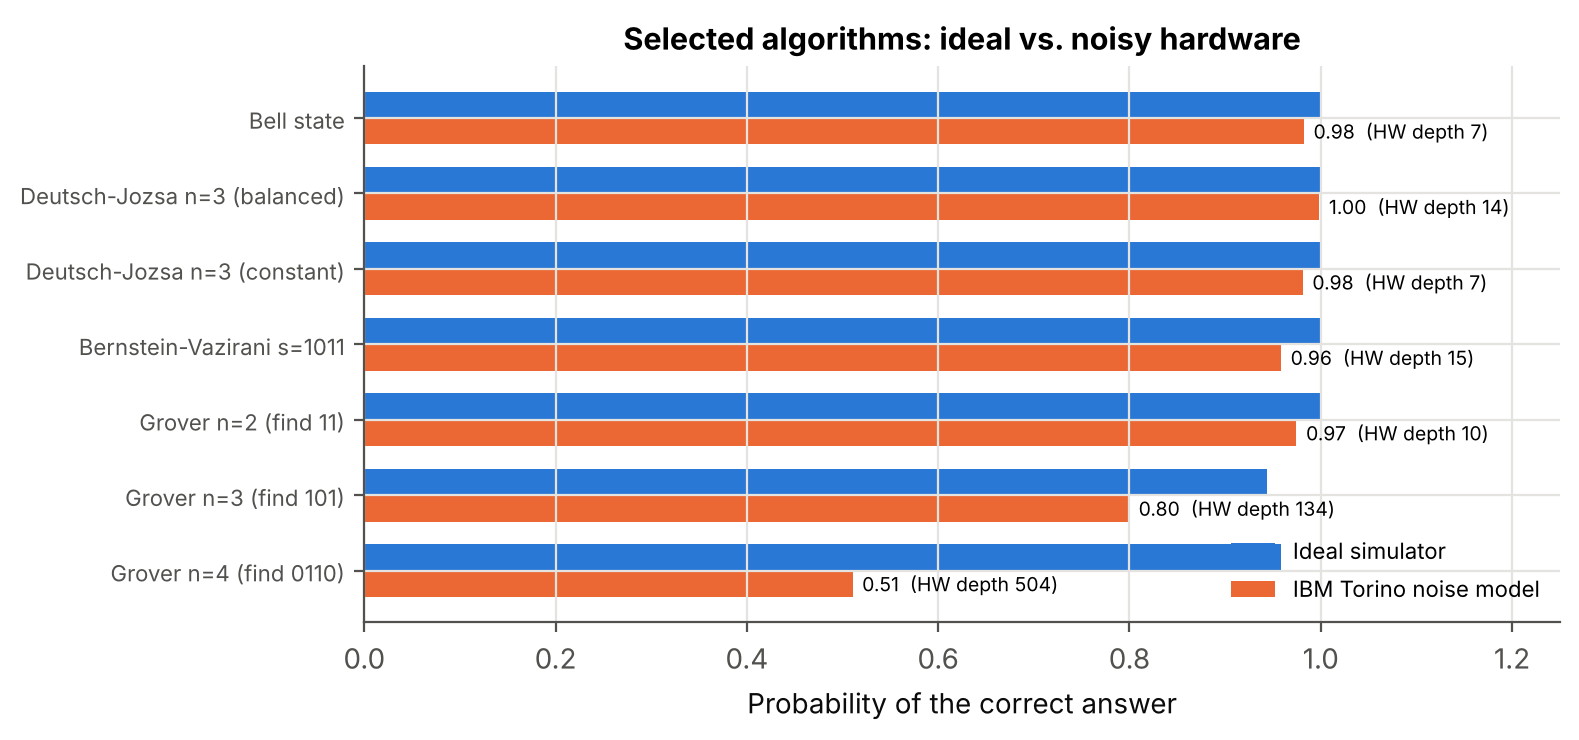

,algorithm,qubits,logical_depth,hardware_depth,hardware_2q_gates,success_ideal,success_noisy,classical_queries_worst,quantum_queries,top_ideal,top_noisy
0,Bell state,2,3,7,1,1.000000,0.982422,NaN,NaN,11,11
1,Deutsch-Jozsa n=3 (balanced),4,6,14,2,1.000000,0.998535,5.0,1.0,101,101
2,Deutsch-Jozsa n=3 (constant),4,4,7,0,1.000000,0.981201,5.0,1.0,0,0
3,Bernstein-Vazirani s=1011,5,7,15,3,1.000000,0.958496,4.0,1.0,1011,1011
4,Grover n=2 (find 11),2,12,10,2,1.000000,0.974609,3.0,1.0,11,11
5,Grover n=3 (find 101),3,22,134,37,0.943848,0.799561,7.0,2.0,101,101
6,Grover n=4 (find 0110),4,38,504,161,0.958496,0.510498,15.0,3.0,110,110


In [10]:
display(Image(R / 'algorithms.png'))
pd.read_csv(R / 'algorithms.csv')